# Dupire Calibration : An implementation

This notebook aims to introduce the Dupire model through an implementation and a calibration on real data. For further information please have a look to my website. This notebook has been built with the following script : Dupire.py, following the same strategy as the Heston model. We will use the CAC 40 implied vol surface

In [3]:
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.interpolate import PchipInterpolator

from forward_curve import ForwardCurve
from Black_Scholes import BlackScholes
from ImpliedVolatilitySurface import ImpliedVolatilitySurface
from Heston import HestonModel
from Heston import TimeDependentHestonModel
from error import CalibrationLoss
from optimizer import Calibrator
from scipy.stats import norm

## 1. Market data

In [4]:
eq_underlying = "CAC40"
S0 = 8042.19
as_of_date = datetime.date(2025, 2, 12)

df_rates = pd.read_csv("../Data/EURIBOR6M_ZCRates_12022025.csv")
df_options = pd.read_csv("../Data/CAC40_MarketOptions_12022025.csv")
zc_rate = PchipInterpolator(df_rates['Expiry'], df_rates['ZCRate'], extrapolate=True)

def third_friday(month, year):
    result = datetime.date(year, month, 15)
    return result.replace(day=15 + (4 - result.weekday()) % 7)

months_nb = {m: i + 1 for i, m in enumerate(["January", "February", "March", "April", "May", "June", "July",
                                             "August", "September", "October", "November", "December"])}
def year_fraction(label):
    month, year = label.split("-")
    return (third_friday(months_nb[month], int(year)) - as_of_date).days / 365

df_options['Expiry'] = df_options['Expiry'].apply(year_fraction)
df_options = df_options.sort_values(['Expiry', 'Strike'])
listed_expiries = list(df_options['Expiry'].unique())
market_strikes = {T: list(g['Strike']) for T, g in df_options.groupby('Expiry')}
call_prices = {T: list(g['Call']) for T, g in df_options.groupby('Expiry')}
put_prices = {T: list(g['Put']) for T, g in df_options.groupby('Expiry')}

## 2. Implied forwards and market implied volatility surface (OTM options)

Implied forward prices :
Expiry 0.0247 : The implied forward is 8048.9992
Expiry 0.1014 : The implied forward is 8066.5029
Expiry 0.1781 : The implied forward is 8079.0076
Expiry 0.3507 : The implied forward is 7943.4967
Expiry 0.6000 : The implied forward is 7987.5051
Expiry 0.8493 : The implied forward is 8003.0029
Expiry 1.0986 : The implied forward is 8039.0017
Expiry 1.3479 : The implied forward is 7931.0008
Expiry 1.5973 : The implied forward is 7944.0029
Expiry 1.8466 : The implied forward is 7969.9974
Expiry 2.8438 : The implied forward is 7897.9984
Expiry 3.8411 : The implied forward is 7872.9996
Expiry 4.8575 : The implied forward is 7847.4946

And its corresponding "Borrow + Dividend" curve :


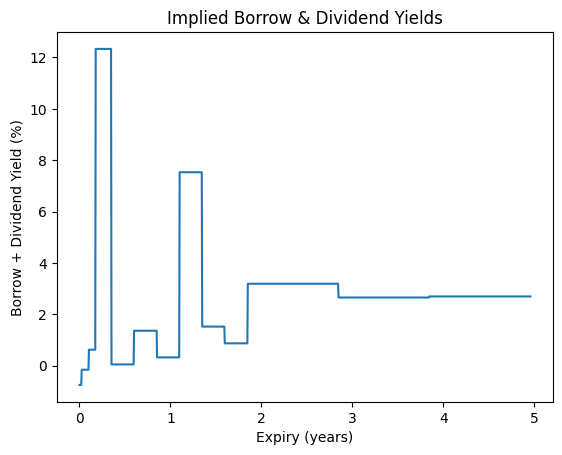

In [5]:
forward_curve = ForwardCurve(S0, zc_rate, listed_expiries, market_strikes, call_prices, put_prices)

otm_options = {T: [p if K <= forward_curve.implied_forwards[T] else c
                   for K, c, p in zip(market_strikes[T], call_prices[T], put_prices[T])]
               for T in listed_expiries}
bs_model = BlackScholes(zc_rate, forward_curve)
market_iv_surface = ImpliedVolatilitySurface(forward_curve, bs_model)
market_iv_surface.set_implied_vol_surface(market_strikes, otm_options)

In [6]:
vol_quotes = pd.DataFrame([
    {"T": T, "K": K, "F": forward_curve.implied_forwards[T], "IV": iv}
    for T in market_iv_surface.expiries
    for K, iv in zip(market_iv_surface.strikes[T], market_iv_surface.implied_vols[T])])
vol_quotes["log_moneyness"] = np.log(vol_quotes["K"] / vol_quotes["F"])
vol_quotes

,T,K,F,IV,log_moneyness
0,0.024658,7925.0,8048.999199,0.147886,-0.015525
1,0.024658,7950.0,8048.999199,0.144939,-0.012376
2,0.024658,7975.0,8048.999199,0.141802,-0.009236
3,0.024658,8000.0,8048.999199,0.138507,-0.006106
4,0.024658,8025.0,8048.999199,0.136136,-0.002986
...,...,...,...,...,...
137,4.857534,8000.0,7847.494553,0.168487,0.019247
138,4.857534,8400.0,7847.494553,0.163171,0.068037
139,4.857534,8800.0,7847.494553,0.159247,0.114557
140,4.857534,9600.0,7847.494553,0.154873,0.201569


## 3. Dupire calibration :


**Dynamics** under the risk-neutral measure:

$$\frac{dS_t}{S_t} = (r - q)\,dt + \sigma_{loc}(S_t, t)\,dW_t$$

**Dupire formula** (in call prices):

$$\sigma_{loc}^2(K,T) = \frac{\partial_T C + (r - q)\,K\,\partial_K C + q\,C}{\frac{1}{2}K^2\,\partial_{KK} C}$$

**Dupire formula** (in total implied variance), with $k = \ln(K/F_T)$ and $w(k,T) = \sigma_{imp}^2(k,T)\,T$:

$$\sigma_{loc}^2(k,T) = \frac{\partial_T w}{1 - \frac{k}{w}\partial_k w + \frac{1}{4}\left(-\frac{1}{4} - \frac{1}{w} + \frac{k^2}{w^2}\right)(\partial_k w)^2 + \frac{1}{2}\partial_{kk} w}$$

**No-arbitrage conditions**

- Calendar: $\partial_T w \geq 0$
- Butterfly: $g(k) = \left(1 - \frac{k w'}{2w}\right)^2 - \frac{w'^2}{4}\left(\frac{1}{w} + \frac{1}{4}\right) + \frac{w''}{2} \geq 0$

**Raw SVI** (one slice per maturity):

$$w(k) = a + b\left(\rho\,(k - m) + \sqrt{(k - m)^2 + \sigma^2}\right)$$

with $b \geq 0$, $|\rho| < 1$, $\sigma > 0$, $a + b\,\sigma\sqrt{1 - \rho^2} \geq 0$.

**Calibration** (for each maturity $T_j$):

$$\min_{a,b,\rho,m,\sigma} \sum_i \omega_i \left(w(k_i) - \sigma_{mkt,i}^2\,T_j\right)^2$$



In [ ]:
import copy

class DupireModel:


    def __init__(self, zc_rate, forward_curve, a = 3, b = 0.04, m = 1 , rho = 0.6, sigma = 0.04 ):


        """
        Dupire Model variables initialization:

        Dupire parameters :

     
        """


        self.sc_rate = zc_rate
        self.forward_curve = forward_curve
        self.sigma = sigma
        self.a = a
        self.b = b
        self.rho = rho
        self.m = m

    @property
    def params(self):
        return {"v0" : self.v0, "theta" : self.theta, "kappa" : self.kappa, "xi": self.xi, "rho": self.rho}




    
        